# Isochrone analysis 

Querying PARSEC: [M/H] = -0.1
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved parsec_isochrones/isochrone_MH_-0.1.csv
Number of points: 626
Columns: ['Zini', 'MH', 'logAge', 'Mini', 'int_IMF', 'Mass', 'logL', 'logTe', 'logg', 'label', 'McoreTP', 'C_O', 'period0', 'period1', 'period2', 'period3', 'period4', 'pmode', 'Mloss', 'tau1m', 'X', 'Y', 'Xc', 'Xn', 'Xo', 'Cexcess', 'Z', 'mbolmag', 'Gmag', 'G_BPmag', 'G_RPmag']

Querying PARSEC: [M/H] = +0.0
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved parsec_isochrones/isochrone_MH_+0.0.csv
Number of points: 642
Columns: ['Zini', 'MH', 'logAge', 'Mini', 'int_IMF', 'Mass', 'logL', 'logTe', 'logg', 'label', 'McoreTP', 'C_O', 'period0', 'period1', 'period2', 'period3', 'period4', 'pmode', 'Mloss', 'tau1m', 'X', 'Y', 'Xc', 'Xn', 'Xo', 'Cexcess', 'Z', 'mbolmag', 'Gmag', 'G_BPmag', 'G_RPmag']

Querying PARSEC: [M/H] = +0.1
Querying http://stev.oapd.inaf.it/cgi-bin/cmd...
Retrieving data...
Saved pa

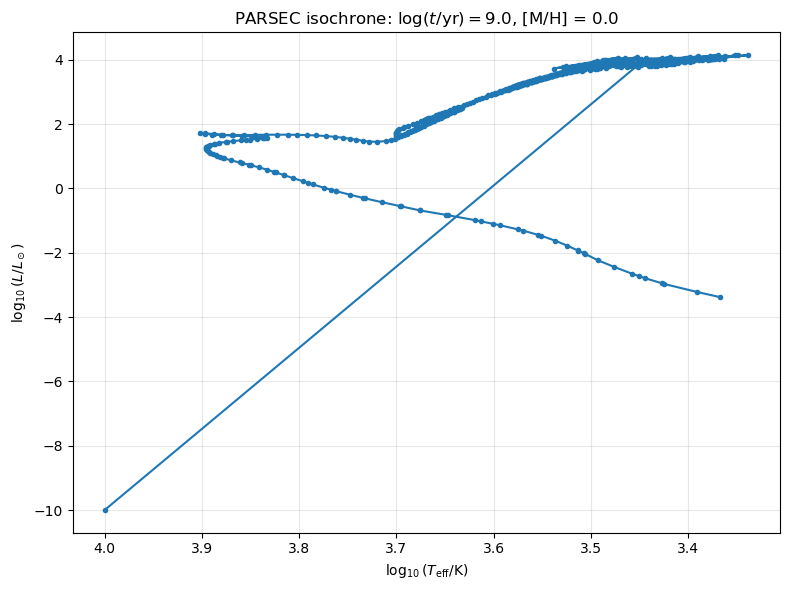

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ezpadova
from pathlib import Path

# Output directory
output_dir = Path("parsec_isochrones")
output_dir.mkdir(exist_ok=True)

# Parameters
logage = 9.0  # log10(age / yr) = 1 Gyr
metallicities = [-0.1, 0.0, 0.1]

# Query PARSEC for each metallicity
isochrones = {}

for mh in metallicities:
    print(f"Querying PARSEC: [M/H] = {mh:+.1f}")

    iso = ezpadova.get_isochrones(
        logage=(logage, logage, 0),
        MH=(mh, mh, 0),
        photsys_file="gaiaEDR3"
    )

    isochrones[mh] = iso

    # Save the complete isochrone
    filename = output_dir / f"isochrone_MH_{mh:+.1f}.csv"
    iso.to_csv(filename, index=False)

    print(f"Saved {filename}")
    print(f"Number of points: {len(iso)}")
    print(f"Columns: {iso.columns.tolist()}\n")


# Plot the solar-metallicity isochrone in the HR diagram
solar_iso = isochrones[0.0]

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    solar_iso["logTe"],
    solar_iso["logL"],
    marker=".",
    linestyle="-"
)

ax.set_xlabel(r"$\log_{10}(T_{\rm eff}/{\rm K})$")
ax.set_ylabel(r"$\log_{10}(L/L_\odot)$")
ax.set_title(rf"PARSEC isochrone: $\log(t/\mathrm{{yr}})={logage}$, [M/H] = 0.0")

# Conventional HR diagram orientation
ax.invert_xaxis()

ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [2]:
mass_grid = np.round(np.arange(1.5, 2.51, 0.1), 1)

solar_iso = isochrones[0.0]

mass_range = solar_iso[
    solar_iso["Mini"].between(1.5, 2.5)
].copy()

print(mass_range[["Mini", "logTe", "logL"]])

         Mini   logTe   logL
50   1.500000  3.8613  0.806
51   1.550000  3.8703  0.876
52   1.591620  3.8768  0.932
53   1.600000  3.8780  0.943
54   1.627203  3.8815  0.979
..        ...     ...    ...
637  2.306444  3.4147  4.020
638  2.306447  3.4174  4.036
639  2.306450  3.4271  4.042
640  2.306453  3.4432  4.043
641  2.306467  4.0000 -9.999

[592 rows x 3 columns]
